# 02 – Data Cleaning and EDA: Texas PM2.5 and Ozone (2020–2024)

We follow the EDA steps from the lecture (EDA slide 5):

1. Provide descriptions of the sample and features
2. Check for missing data
3. Check for duplicates
4. Identify the shape of the data
5. Identify significant correlations
6. Spot / deal with outliers

and the data-quality and preprocessing ideas from the **Data** lecture: attribute types, missing values, duplicate data, aggregation, noise and outliers.

The original and combined files are **not changed**. The cleaned data is saved as new files in `Cleaned_Data/`.

## 0. Load the combined files

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
DATA = ".."

# keep_default_na=False so EPA's event_type "None" is not read as missing
pm = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_PM25_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)
oz = pd.read_csv(f"{DATA}/Combined_Datasets/Texas_Ozone_Combined.csv",
                 keep_default_na=False, na_values=[""], low_memory=False)

# keep track of the row counts after each step
steps = [{"step": "0. Combined file", "PM2.5 rows": len(pm), "Ozone rows": len(oz)}]

## 1. Describe the sample and the features (EDA slides 9–11)

### 1.1 How many rows and columns? (`df.shape`)

In [2]:
print("PM2.5:", pm.shape, " -> ", pm.shape[0], "observations,", pm.shape[1], "features")
print("Ozone:", oz.shape, " -> ", oz.shape[0], "observations,", oz.shape[1], "features")

PM2.5: (164219, 34)  ->  164219 observations, 34 features
Ozone: (129633, 34)  ->  129633 observations, 34 features


Each **object** (row) is one monitor's daily summary, and each **attribute** (column) is a property of it (Data slide 2).

### 1.2 What type of data? (`df.info()`)

In [3]:
pm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164219 entries, 0 to 164218
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   site_id              164219 non-null  object 
 1   year                 164219 non-null  int64  
 2   pollutant            164219 non-null  object 
 3   state_code           164219 non-null  int64  
 4   county_code          164219 non-null  int64  
 5   site_num             164219 non-null  int64  
 6   parameter_code       164219 non-null  int64  
 7   poc                  164219 non-null  int64  
 8   latitude             164219 non-null  float64
 9   longitude            164219 non-null  float64
 10  datum                164219 non-null  object 
 11  parameter_name       164219 non-null  object 
 12  sample_duration      164219 non-null  object 
 13  pollutant_standard   83863 non-null   object 
 14  date_local           164219 non-null  object 
 15  units_of_measure 

### 1.3 Attribute types (Data slides 5–10)
The type of an attribute decides which statistics and plots make sense: mode for nominal, median for ordinal, mean and standard deviation for interval/ratio (Data slide 8). The attributes we use later are:

| Attribute | Type | Discrete / continuous | Why |
|---|---|---|---|
| `site_id`, `poc`, `county_name`, `city_name`, `local_site_name`, `cbsa_name`, `method_name` | **Nominal** | discrete | names / ID numbers: only "=" or "≠" make sense |
| `sample_duration`, `event_type` | **Nominal** | discrete | labels for the kind of record |
| `aqi` | **Ordinal** in use (Good, Moderate, Unhealthy, …), stored as numbers | discrete | the categories are ordered |
| `date_local`, `year` | **Interval** | discrete | differences between dates make sense, but there is no "zero date" |
| `latitude`, `longitude` | **Interval** | continuous | position on a scale with an arbitrary zero |
| `arithmetic_mean`, `first_max_value` (concentrations) | **Ratio** | continuous | a true zero exists (no pollutant), so 20 µg/m³ really is twice 10 µg/m³ |
| `observation_count` | **Ratio** | discrete | a count |
| `observation_percent` | **Ratio** | continuous | a percentage of a count |

### 1.4 Summary statistics (`df.describe()`)

In [4]:
print("PM2.5 (µg/m³):")
display(pm[["arithmetic_mean", "first_max_value", "aqi", "observation_count", "observation_percent"]].describe().round(2))
print("Ozone (ppm):")
display(oz[["arithmetic_mean", "first_max_value", "aqi", "observation_count", "observation_percent"]].describe().round(4))

PM2.5 (µg/m³):


,arithmetic_mean,first_max_value,aqi,observation_count,observation_percent
count,164219.00,164219.00,83863.00,164219.00,164219.00
mean,9.12,13.92,43.53,12.01,99.00
std,5.74,12.08,17.40,11.35,6.29
min,-3.62,-3.60,0.00,1.00,4.00
25%,5.50,7.40,31.00,1.00,100.00
50%,7.90,11.50,44.00,1.00,100.00
75%,11.20,17.00,55.00,24.00,100.00
max,234.00,724.60,263.00,24.00,100.00


Ozone (ppm):


,arithmetic_mean,first_max_value,aqi,observation_count,observation_percent
count,129633.0000,129633.0000,129633.0000,129633.0000,129633.0000
mean,0.0299,0.0389,38.0584,16.7362,98.4531
std,0.0109,0.0131,17.9419,1.3435,7.8755
min,-0.0017,-0.0010,0.0000,1.0000,6.0000
25%,0.0218,0.0300,28.0000,17.0000,100.0000
50%,0.0292,0.0380,35.0000,17.0000,100.0000
75%,0.0373,0.0470,44.0000,17.0000,100.0000
max,0.0854,0.1140,209.0000,17.0000,100.0000


- **PM2.5** daily means are mostly between about 6 and 12 µg/m³, with a long right tail (the maximum is far above the 75th percentile). There are a few small **negative** values, which we look at in Section 6.
- **Ozone** `first_max_value` is the **daily maximum 8-hour average (MDA8)**, the value the ozone standard and the AQI use. Most days fall between 0.030 and 0.047 ppm.
- For ozone, `observation_count` is not always 17 and `observation_percent` is not always 100. Some days are **incomplete**, which we handle in Section 2.

### 1.5 Which kinds of records are in the files?

In [5]:
print("PM2.5 sample_duration:")
print(pm["sample_duration"].value_counts(), "\n")
print("Ozone event_type:")
print(oz["event_type"].value_counts())

PM2.5 sample_duration:
sample_duration
1 HOUR           80356
24-HR BLK AVG    78341
24 HOUR           5522
Name: count, dtype: int64 

Ozone event_type:
event_type
None        129226
Included       391
Excluded        16
Name: count, dtype: int64


- **PM2.5:** continuous monitors report a `1 HOUR` row **and** a `24-HR BLK AVG` row for the same day. Filter-based monitors report a `24 HOUR` row.
- **Ozone:** almost every row has `event_type = None`. On a few monitor-days EPA published two versions, with the exceptional-event hours **Included** and **Excluded**.

These are **duplicate records** of the same measurement, which we handle in Section 3.

## 2. Check for missing data (EDA slide 12; Data slide 27)

### 2.1 Missing values in the columns (`df.isnull().sum()`)

In [6]:
missing = pd.DataFrame({"PM2.5": pm.isnull().sum(), "Ozone": oz.isnull().sum()})
missing[(missing > 0).any(axis=1)]

,PM2.5,Ozone
pollutant_standard,80356,0
aqi,80356,0
method_code,0,1
local_site_name,3469,0
cbsa_name,3240,3849
record_note,83775,129617


- `pollutant_standard` and `aqi` are empty for exactly the 80,356 PM2.5 `1 HOUR` rows. EPA does not compute an AQI for those records, and they are removed as duplicates in Section 3, so this goes away.
- `record_note` is a note column added when the files were combined; it is empty for most rows by design.
- `method_code` is missing for one ozone row. We don't use that column.
- The rest are **names**: `local_site_name` is missing for one PM2.5 site that EPA did not name, and `cbsa_name` (metro area) is missing for rural counties that are not in a metro area.

None of these are measurements, and none are used as model inputs, so we **ignore them** (Data slide 27: "ignore the missing value during analysis").

### 2.2 Missing hours inside a day: incomplete ozone days
A day's ozone value can be built from **incomplete** hourly data. Each ozone day has up to **17** eight-hour averages (the ones starting 7 AM to 11 PM), and EPA treats a day as complete when at least **75%** of them were measured, which is 13 of 17.

In [7]:
print("Ozone days by number of 8-hour averages measured (last rows):")
print(oz.groupby("observation_count").size().tail(6))
print()
low_pm = pm["observation_percent"] < 75
print("PM2.5 rows below 75% complete:", low_pm.sum(), "-> their record types:", pm.loc[low_pm, "sample_duration"].unique())

Ozone days by number of 8-hour averages measured (last rows):
observation_count
12      1064
13       825
14       636
15       483
16       321
17    123470
dtype: int64

PM2.5 rows below 75% complete: 2016 -> their record types: ['1 HOUR']


Most ozone days have all 17 averages, but some have fewer. The incomplete PM2.5 rows are all `1 HOUR` records, which are removed as duplicates in Section 3. The official PM2.5 daily averages are all at least 75% complete.

**Watch out for December 31.** The late 8-hour averages of Dec 31 need hours from Jan 1, which are in the next year's file. So on Dec 31 only **12** averages are possible, and `observation_percent` can never be above 71%. Using `observation_percent < 75` directly would delete **every** Dec 31, even fully measured ones.

In [8]:
dec31 = oz["date_local"].str[5:] == "12-31"
print("Dec 31 rows:", dec31.sum())
print(oz[dec31].groupby(["observation_count", "observation_percent"]).size())

Dec 31 rows: 354
observation_count  observation_percent
7                  41.0                     1
8                  47.0                     3
10                 59.0                     2
11                 65.0                    68
12                 71.0                   280
dtype: int64


So we compute completeness against what was **possible** that day: 17 averages normally, 12 on Dec 31.

In [9]:
oz["possible_averages"] = 17
oz.loc[dec31, "possible_averages"] = 12
oz["percent_complete"] = (100 * oz["observation_count"] / oz["possible_averages"]).round(1)

incomplete = oz["percent_complete"] < 75
print("Incomplete ozone days:", incomplete.sum(), f"({100 * incomplete.mean():.1f}% of rows)")
print("Rows that observation_percent < 75 would have removed:", (oz["observation_percent"] < 75).sum())
print()
print("Median MDA8 (ppm) - complete days:", oz.loc[~incomplete, "first_max_value"].median(),
      "| incomplete days:", oz.loc[incomplete, "first_max_value"].median())

Incomplete ozone days: 3548 (2.7% of rows)
Rows that observation_percent < 75 would have removed: 3889

Median MDA8 (ppm) - complete days: 0.038 | incomplete days: 0.034


**Why remove them?** Incomplete days read **lower** (median 0.034 vs. 0.038 ppm). The missing hours are often the afternoon, when ozone is highest, so these values are not comparable with complete days. Data slide 27 lists **"eliminate data objects"** as one way to handle missing values, and we use it here. Estimating the missing hours would mean guessing the most important part of the day.

## 3. Check for duplicates (EDA slide 12; Data slide 28)

Data slide 28: duplicates are "a major issue when merging data from heterogeneous sources". We have three kinds:

1. **PM2.5 `1 HOUR` vs. `24-HR BLK AVG` rows:** two rows for the same monitor and day, holding the same measurement (one built from hourly data, one the official daily average).
2. **Ozone "Excluded" vs. "Included" rows:** two versions of the same monitor-day.
3. **PM2.5 sites with 2+ monitors** (different `poc`): not duplicates, but several measurements of the same site-day (Section 3.3).

### 3.1 Exact duplicate rows (`df.duplicated()`)

In [10]:
print("Fully identical rows - PM2.5:", pm.duplicated().sum(), "| Ozone:", oz.duplicated().sum())

Fully identical rows - PM2.5: 0 | Ozone: 0


No row is an exact copy. The duplicates are **near-duplicates**: the same monitor and day, but a different record type.

### 3.2 Same monitor, same day

In [11]:
key = ["site_id", "poc", "date_local"]
print("PM2.5 monitor-days with more than one row:", pm.duplicated(key).sum())
print("Ozone monitor-days with more than one row:", oz.duplicated(key).sum())

# example: one PM2.5 monitor-day with both record types
ex = pm[pm.duplicated(key, keep=False)].sort_values(key).head(2)
ex[["site_id", "poc", "date_local", "sample_duration", "arithmetic_mean", "analysis_record"]]

PM2.5 monitor-days with more than one row: 78341
Ozone monitor-days with more than one row: 16


,site_id,poc,date_local,sample_duration,arithmetic_mean,analysis_record
0,48-013-1090,1,2020-05-29,1 HOUR,5.666667,False
1,48-013-1090,1,2020-05-29,24-HR BLK AVG,5.600000,True


The `analysis_record` column (added when the files were combined, see `Documentation/02_filter_clean_combine.py`) marks **one** record per monitor-day: the official `24-HR BLK AVG` / `24 HOUR` row for PM2.5, and the **Included** row for ozone (the air people actually breathed). We keep those and drop the rest.

In [12]:
print("PM2.5 rows being removed, by type:")
print(pm[~pm["analysis_record"]]["sample_duration"].value_counts(), "\n")
print("Ozone rows being removed, by type:")
print(oz[~oz["analysis_record"]]["event_type"].value_counts())

pm1 = pm[pm["analysis_record"]].copy()
oz1 = oz[oz["analysis_record"]].copy()
print()
print("PM2.5:", len(pm), "->", len(pm1), "rows  (removed", len(pm) - len(pm1), ")")
print("Ozone:", len(oz), "->", len(oz1), "rows  (removed", len(oz) - len(oz1), ")")
print("Monitor-days still duplicated - PM2.5:", pm1.duplicated(key).sum(), "| Ozone:", oz1.duplicated(key).sum())
steps.append({"step": "1. Remove duplicate records", "PM2.5 rows": len(pm1), "Ozone rows": len(oz1)})

PM2.5 rows being removed, by type:
sample_duration
1 HOUR    80356
Name: count, dtype: int64 

Ozone rows being removed, by type:
event_type
Excluded    16
Name: count, dtype: int64



PM2.5: 164219 -> 83863 rows  (removed 80356 )
Ozone: 129633 -> 129617 rows  (removed 16 )


Monitor-days still duplicated - PM2.5: 0 | Ozone: 0


Now we remove the incomplete ozone days from Section 2.2:

Ozone: 129617 -> 126078 rows  (removed 3539 incomplete days)


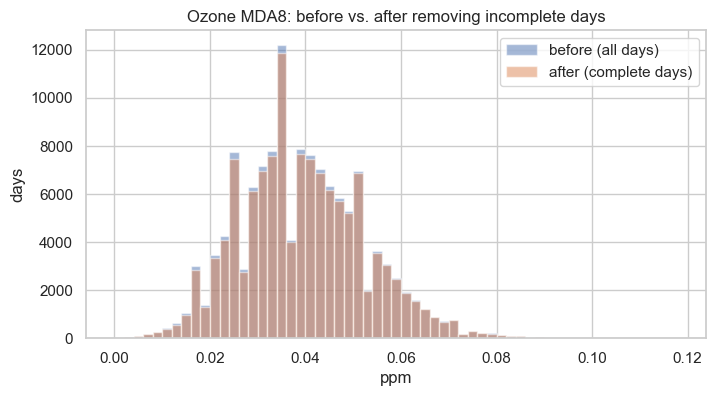

Mean before: 0.0389 | mean after: 0.039


In [13]:
incomplete1 = oz1["percent_complete"] < 75
oz2 = oz1[~incomplete1].copy()
pm2 = pm1.copy()
print("Ozone:", len(oz1), "->", len(oz2), "rows  (removed", incomplete1.sum(), "incomplete days)")
steps.append({"step": "2. Remove incomplete ozone days", "PM2.5 rows": len(pm2), "Ozone rows": len(oz2)})

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 0.12, 0.002)
ax.hist(oz1["first_max_value"], bins=bins, alpha=0.5, label="before (all days)")
ax.hist(oz2["first_max_value"], bins=bins, alpha=0.5, label="after (complete days)")
ax.set_title("Ozone MDA8: before vs. after removing incomplete days")
ax.set_xlabel("ppm"); ax.set_ylabel("days")
ax.legend()
plt.show()
print("Mean before:", round(oz1["first_max_value"].mean(), 4), "| mean after:", round(oz2["first_max_value"].mean(), 4))

Removing under 3% of the rows barely moves the overall distribution, but it removes a downward bias at the sites that have many incomplete days.

### 3.3 Several monitors at one site: aggregation (Data slides 31–32)
Some PM2.5 sites have two or more monitors measuring on the same day. These are real, separate instruments, but if we count rows, those sites get extra weight. Data slide 31 describes **aggregation**: combining several objects into one, which also gives "more stable" values. We **average the monitors** to get one PM2.5 value per site per day.

In [14]:
pm_counts = pm2.groupby(["site_id", "date_local"]).size()
oz_counts = oz2.groupby(["site_id", "date_local"]).size()
print("PM2.5 site-days with more than one monitor:", (pm_counts > 1).sum())
print("Ozone site-days with more than one monitor:", (oz_counts > 1).sum(), "-> ozone is already one row per site-day")

example = pm_counts[pm_counts > 1].index[0]
pm2[(pm2["site_id"] == example[0]) & (pm2["date_local"] == example[1])][
    ["site_id", "date_local", "poc", "method_name", "arithmetic_mean", "aqi"]]

PM2.5 site-days with more than one monitor: 7047
Ozone site-days with more than one monitor: 0 -> ozone is already one row per site-day


,site_id,date_local,poc,method_name,arithmetic_mean,aqi
1142,48-029-0032,2020-01-04,1,R & P Model 2025 PM-2.5 Sequential Air Sampler...,5.2,29.0
1180,48-029-0032,2020-01-04,2,Met One BAM-1022 Mass Monitor w/ VSCC or TE-PM...,5.6,31.0


In [15]:
site_info = ["county_name", "city_name", "local_site_name", "cbsa_name", "latitude", "longitude"]

pm_clean = pm2.groupby(["site_id", "date_local"]).agg(
    year=("year", "first"),
    county_name=("county_name", "first"),
    city_name=("city_name", "first"),
    local_site_name=("local_site_name", "first"),
    cbsa_name=("cbsa_name", "first"),
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    pm25_ugm3=("arithmetic_mean", "mean"),
    pm25_aqi=("aqi", "max"),
    n_monitors=("poc", "count"),
).reset_index()
pm_clean["pm25_ugm3"] = pm_clean["pm25_ugm3"].round(2)

oz_clean = oz2[["site_id", "date_local", "year"] + site_info +
               ["first_max_value", "arithmetic_mean", "aqi", "percent_complete"]].rename(columns={
    "first_max_value": "ozone_mda8_ppm",
    "arithmetic_mean": "ozone_daily_mean_ppm",
    "aqi": "ozone_aqi",
}).reset_index(drop=True)

print("PM2.5:", len(pm2), "->", len(pm_clean), "rows  (", len(pm2) - len(pm_clean), "monitor rows combined into their site-day)")
print("Ozone:", len(oz_clean), "rows")
steps.append({"step": "3. One row per site-day", "PM2.5 rows": len(pm_clean), "Ozone rows": len(oz_clean)})
pm_clean[(pm_clean["site_id"] == example[0]) & (pm_clean["date_local"] == example[1])]

PM2.5: 83863 -> 76660 rows  ( 7203 monitor rows combined into their site-day)
Ozone: 126078 rows


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,pm25_ugm3,pm25_aqi,n_monitors
3348,48-029-0032,2020-01-04,2020,Bexar,Leon Valley,San Antonio Northwest,"San Antonio-New Braunfels, TX",29.515061,-98.620211,5.4,31.0,2


- `pm25_ugm3` = average of the monitors at that site that day
- `pm25_aqi` = the highest AQI of those monitors (EPA reports the worst monitor for a site's daily AQI)
- `n_monitors` = how many monitors were averaged
- For ozone, `ozone_mda8_ppm` (MDA8) is the main value. `ozone_daily_mean_ppm` is the 24-hour average.

### 3.4 Is the data balanced? (EDA slides 13, 15)
EDA slide 13 checks whether every group has the same number of observations (`value_counts`). Our "groups" are **years** and **sites**. If one year or one site had many more rows, it would weigh more in any average or model.

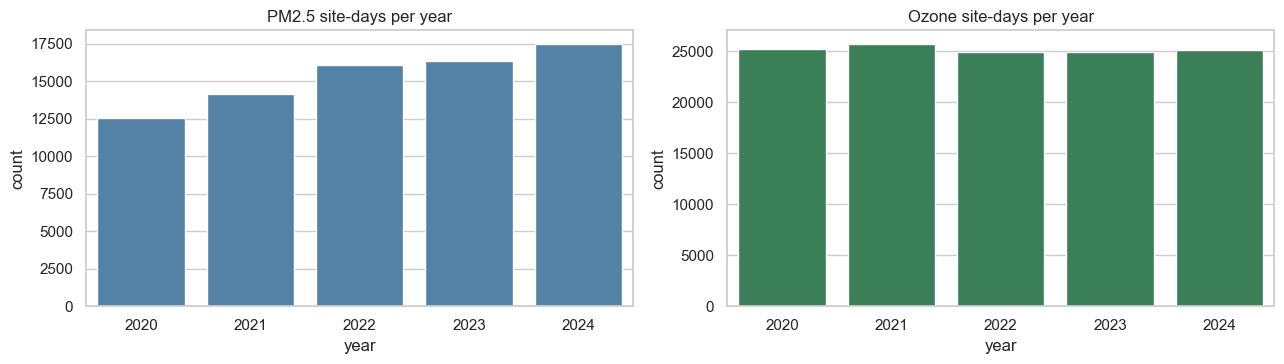

Site-days per site:


,PM2.5,Ozone
count,57.0,76.0
mean,1345.0,1659.0
std,556.0,244.0
min,21.0,347.0
25%,1162.0,1676.0
50%,1664.0,1738.0
75%,1735.0,1760.0
max,1783.0,1796.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.countplot(x="year", data=pm_clean, ax=axes[0], color="steelblue")
axes[0].set_title("PM2.5 site-days per year")
sns.countplot(x="year", data=oz_clean, ax=axes[1], color="seagreen")
axes[1].set_title("Ozone site-days per year")
plt.tight_layout()
plt.show()

per_site = pd.DataFrame({"PM2.5": pm_clean.value_counts("site_id").describe(),
                         "Ozone": oz_clean.value_counts("site_id").describe()}).round(0)
print("Site-days per site:")
per_site

- **Ozone years are balanced** (about 25,000 site-days each year).
- **PM2.5 years are not:** site-days grow from 12,550 in 2020 to 17,519 in 2024, as more daily monitors came online. Statewide PM2.5 totals or averages that mix all years lean toward later years.
- **Sites:** half the ozone sites have at least 1,738 days (of 1,827 possible), but the smallest has 347. PM2.5 is much less even, from 21 to 1,783 days per site. Some sites started or stopped during 2020–2024, and filter monitors only sample every 3rd or 6th day. When we compare sites, we use **per-site averages** so sites with many days don't dominate.

## 4. Identify the shape of the data (EDA slides 14–21)

### 4.1 Histograms (EDA slide 20)

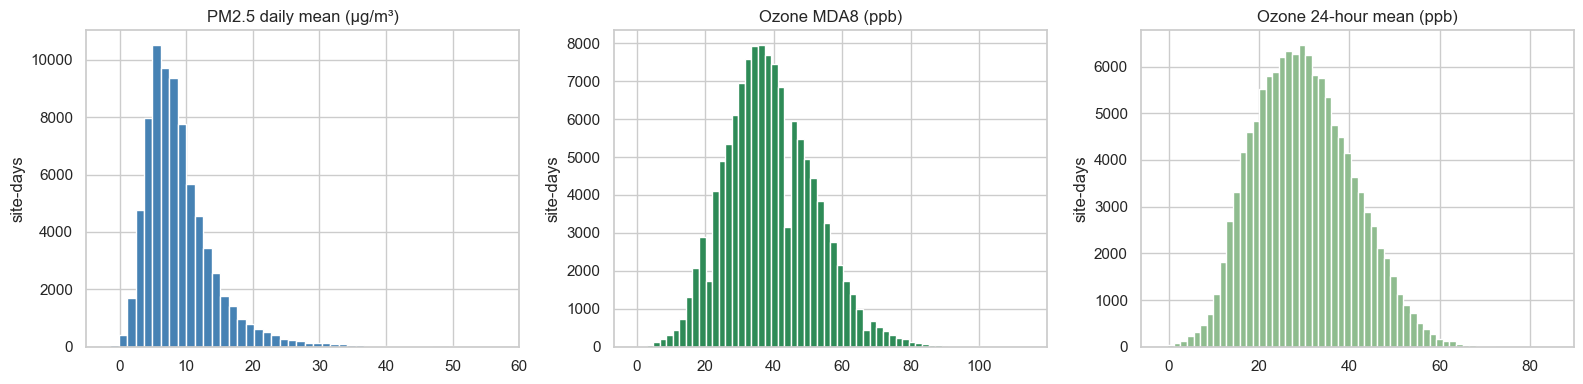

Skewness - PM2.5: 3.13 | ozone MDA8: 0.4


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(pm_clean["pm25_ugm3"], bins=150, color="steelblue")
axes[0].set_xlim(-5, 60)
axes[0].set_title("PM2.5 daily mean (µg/m³)")
axes[1].hist(oz_clean["ozone_mda8_ppm"] * 1000, bins=60, color="seagreen")
axes[1].set_title("Ozone MDA8 (ppb)")
axes[2].hist(oz_clean["ozone_daily_mean_ppm"] * 1000, bins=60, color="darkseagreen")
axes[2].set_title("Ozone 24-hour mean (ppb)")
for ax in axes:
    ax.set_ylabel("site-days")
plt.tight_layout()
plt.show()

print("Skewness - PM2.5:", round(pm_clean["pm25_ugm3"].skew(), 2),
      "| ozone MDA8:", round(oz_clean["ozone_mda8_ppm"].skew(), 2))

- **PM2.5 is strongly right-skewed** (skewness 3.1). Most days are 5–12 µg/m³, but a long tail reaches over 100 µg/m³, so a few events are far above normal.
- **Ozone MDA8 is close to symmetric** (skewness 0.4), centered near 38 ppb, with a shorter right tail of high days.
- The ozone 24-hour mean is lower than the MDA8, as expected, because it includes the night hours when ozone is low.

### 4.2 Distribution by year and season: box plots and violin plots (EDA slides 18, 28)

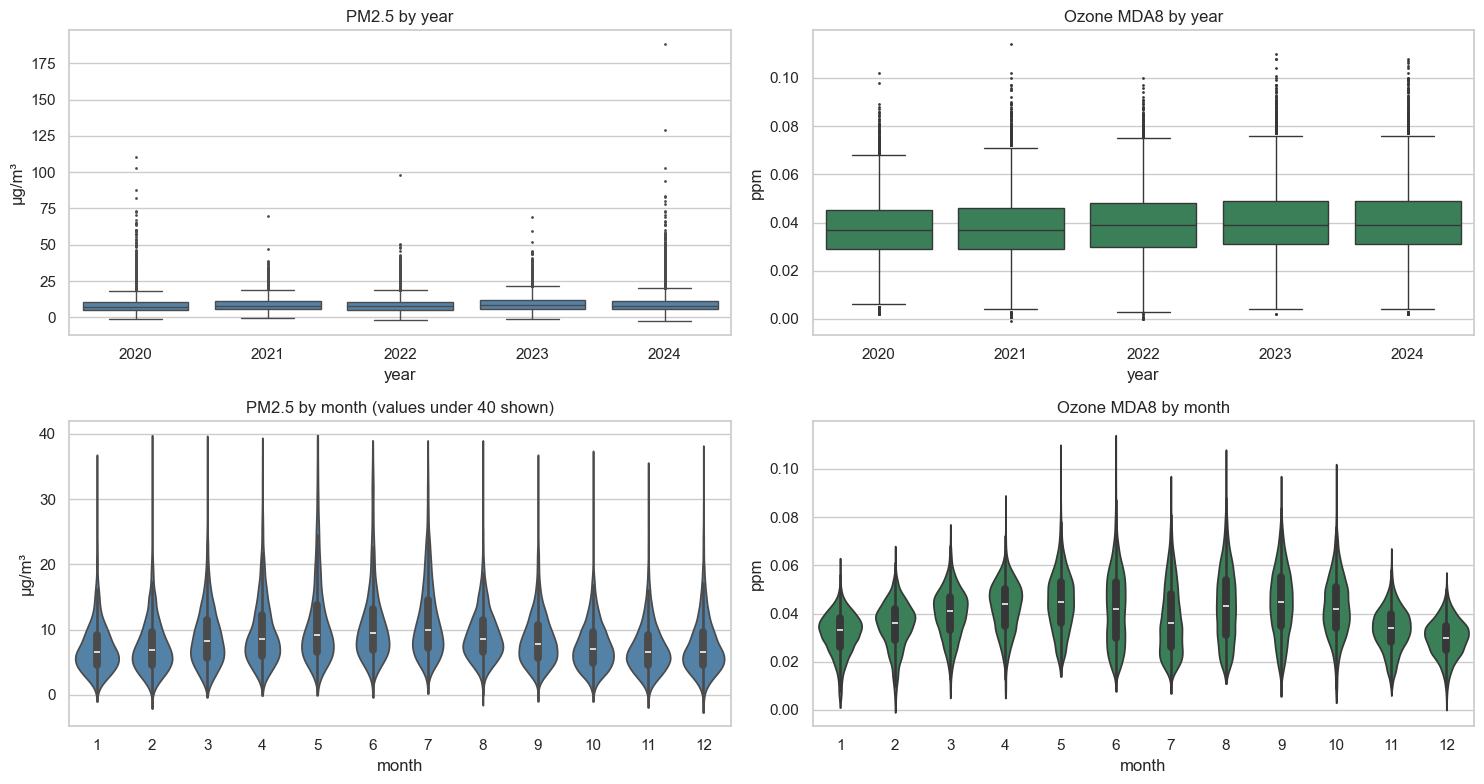

In [18]:
pm_clean["month"] = pd.to_datetime(pm_clean["date_local"]).dt.month
oz_clean["month"] = pd.to_datetime(oz_clean["date_local"]).dt.month

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
sns.boxplot(data=pm_clean, x="year", y="pm25_ugm3", ax=axes[0, 0], fliersize=1, color="steelblue")
axes[0, 0].set_title("PM2.5 by year"); axes[0, 0].set_ylabel("µg/m³")
sns.boxplot(data=oz_clean, x="year", y="ozone_mda8_ppm", ax=axes[0, 1], fliersize=1, color="seagreen")
axes[0, 1].set_title("Ozone MDA8 by year"); axes[0, 1].set_ylabel("ppm")
sns.violinplot(data=pm_clean[pm_clean["pm25_ugm3"] < 40], x="month", y="pm25_ugm3", ax=axes[1, 0],
               color="steelblue", cut=0)
axes[1, 0].set_title("PM2.5 by month (values under 40 shown)"); axes[1, 0].set_ylabel("µg/m³")
sns.violinplot(data=oz_clean, x="month", y="ozone_mda8_ppm", ax=axes[1, 1], color="seagreen", cut=0)
axes[1, 1].set_title("Ozone MDA8 by month"); axes[1, 1].set_ylabel("ppm")
plt.tight_layout()
plt.show()

- **By year:** the medians change little (PM2.5 7.5 → 8.2 µg/m³, ozone 37 → 39 ppb from 2020 to 2024). 2023–2024 PM2.5 has a higher upper range: the 90th percentile rose from about 15 to about 16.5 µg/m³.
- **By month:** ozone has a clear **seasonal shape**: lowest in December–January (median 30–33 ppb), high in April–May and again in August–September (44–45 ppb), with a dip in July. PM2.5 rises from about 6.5 µg/m³ in winter to about 10 in **July**, the season when Saharan dust reaches Texas. Both pollutants follow the calendar.

## 5. Identify significant correlations (EDA slides 23–26)
We compute the Pearson correlation (`data.corr(method="pearson")`) between the measurements. To compare PM2.5 and ozone we join them on site and day, which only works at sites that measure both.

Site-days with both PM2.5 and ozone: 34598 at 28 sites


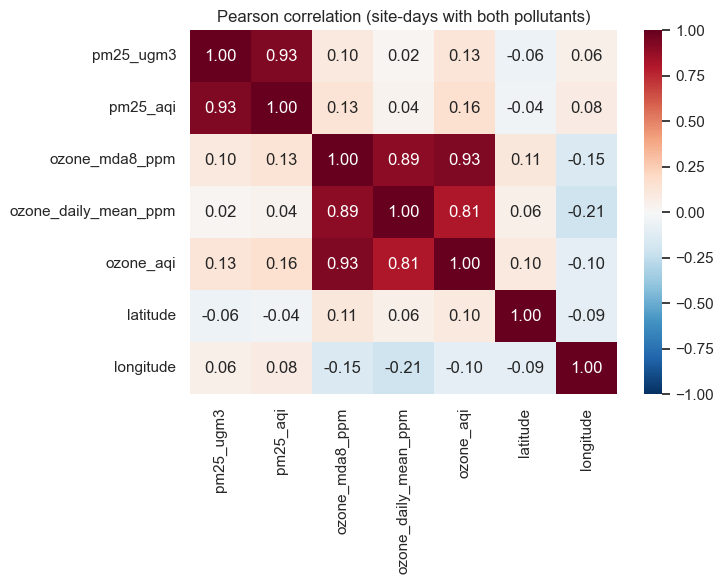

In [19]:
both = pm_clean.merge(oz_clean, on=["site_id", "date_local"], suffixes=("", "_oz"))
print("Site-days with both PM2.5 and ozone:", len(both), "at", both["site_id"].nunique(), "sites")
corr = both[["pm25_ugm3", "pm25_aqi", "ozone_mda8_ppm", "ozone_daily_mean_ppm", "ozone_aqi",
             "latitude", "longitude"]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation (site-days with both pollutants)")
plt.tight_layout()
plt.show()

- **Each pollutant with its own AQI:** r = 0.93 for both PM2.5 and ozone, as expected, since the AQI is computed from the concentration. This makes the AQI a **redundant** feature (Data slide 53) for analysis.
- **Ozone MDA8 vs. ozone 24-hour mean:** r = 0.89. Strongly related, but not the same thing (peak vs. whole-day average).
- **PM2.5 vs. ozone:** r = 0.10, a very weak positive correlation. The two pollutants vary almost **independently**, so they need separate analyses.
- **Location:** weak correlations with latitude/longitude (|r| ≤ 0.21).

**Caution (EDA slide 26):** correlation is not causation, and correlations can be misleading when a confounding variable such as **season** is ignored. Both pollutants follow the calendar, which can create or hide a relationship (Simpson's paradox).

## 6. Spot and deal with outliers (EDA slides 27–30; Data slides 25–26)

### 6.1 Detecting outliers with box plots / the IQR rule
A box plot marks as an outlier any value more than **1.5 × IQR** below Q1 or above Q3 (IQR = Q3 − Q1). This is the rule on EDA slides 29–30.

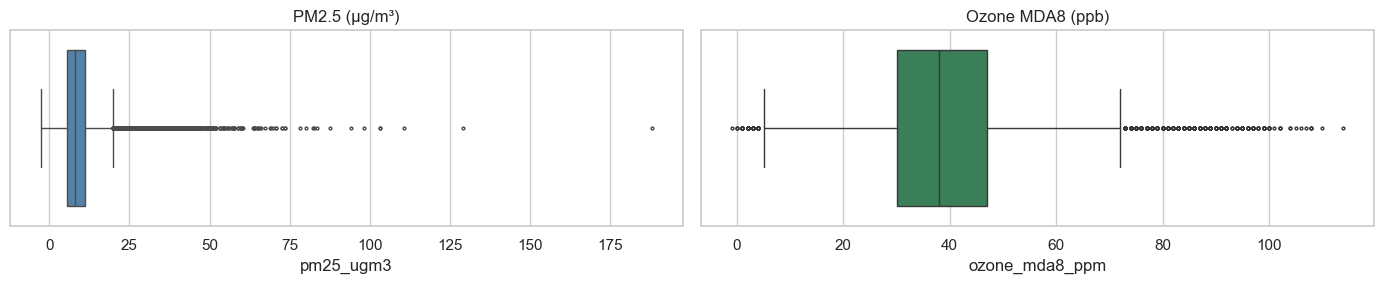

,lower fence,upper fence,outliers,% of site-days
PM2.5 (µg/m³),-3.05,19.75,3498,4.56
Ozone MDA8 (ppb),4.50,72.50,1455,1.15


In [20]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return low, high, (s < low) | (s > high)

pm_low, pm_high, pm_out = iqr_outliers(pm_clean["pm25_ugm3"])
oz_low, oz_high, oz_out = iqr_outliers(oz_clean["ozone_mda8_ppm"] * 1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
sns.boxplot(x=pm_clean["pm25_ugm3"], ax=axes[0], color="steelblue", fliersize=2)
axes[0].set_title("PM2.5 (µg/m³)")
sns.boxplot(x=oz_clean["ozone_mda8_ppm"] * 1000, ax=axes[1], color="seagreen", fliersize=2)
axes[1].set_title("Ozone MDA8 (ppb)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "lower fence": [pm_low, oz_low], "upper fence": [pm_high, oz_high],
    "outliers": [pm_out.sum(), oz_out.sum()],
    "% of site-days": [100 * pm_out.mean(), 100 * oz_out.mean()],
}, index=["PM2.5 (µg/m³)", "Ozone MDA8 (ppb)"]).round(2)

### 6.2 What are these outliers?
EDA slide 29: outliers "can be caused by measurement or execution errors". Data slide 26 adds that outliers can be **noise** (case 1) or **the goal of the analysis** (case 2). So before removing anything, we look at **when** they happen:

In [21]:
pm_out_days = pm_clean[pm_out & (pm_clean["pm25_ugm3"] > pm_high)]
print("Dates with the most PM2.5 high outliers (number of sites):")
print(pm_out_days["date_local"].value_counts().head(8))
print()
print("PM2.5 high outliers by month:")
print(pm_out_days["month"].value_counts().sort_index().to_string())

Dates with the most PM2.5 high outliers (number of sites):
date_local
2024-07-31    45
2022-06-13    43
2022-07-17    42
2022-06-14    42
2022-06-16    41
2024-05-25    40
2024-05-27    38
2024-05-08    38
Name: count, dtype: int64

PM2.5 high outliers by month:
month
1     143
2     105
3     209
4     360
5     822
6     640
7     687
8     136
9     149
10     65
11     50
12    132


In [22]:
oz_out_days = oz_clean[oz_out & (oz_clean["ozone_mda8_ppm"] * 1000 > oz_high)]
print("Ozone high outliers by month:")
print(oz_out_days["month"].value_counts().sort_index().to_string())
print()
print("Ozone high outliers by metro area:")
print(oz_out_days["cbsa_name"].value_counts().head(5).to_string())

Ozone high outliers by month:
month
3       4
4      14
5     174
6     241
7     160
8     380
9     271
10    121

Ozone high outliers by metro area:
cbsa_name
Houston-The Woodlands-Sugar Land, TX    605
Dallas-Fort Worth-Arlington, TX         518
El Paso, TX                              98
San Antonio-New Braunfels, TX            51
Beaumont-Port Arthur, TX                 22


In [23]:
standards = pd.DataFrame({
    "EPA daily level": ["35 µg/m³", "70 ppb"],
    "site-days at or above it": [(pm_clean["pm25_ugm3"] >= 35).sum(), (oz_clean["ozone_mda8_ppm"] >= 0.070).sum()],
    "of those, flagged as IQR outliers": [(pm_out & (pm_clean["pm25_ugm3"] >= 35)).sum(),
                                          (oz_out & (oz_clean["ozone_mda8_ppm"] >= 0.070)).sum()],
}, index=["PM2.5", "Ozone"])
standards

,EPA daily level,site-days at or above it,"of those, flagged as IQR outliers"
PM2.5,35 µg/m³,370,370
Ozone,70 ppb,2121,1365


**What the outliers are:**
- **PM2.5** high outliers are concentrated in **May–July** (2,149 of 3,498). That is when Saharan dust reaches Texas and when smoke from spring agricultural fires in Mexico and Central America drifts north. On the top dates, **40–45 sites are high on the same day** (for example 2024-07-31 and 2022-06-13 to 06-16), which is what real regional events look like. A broken instrument would only affect one site. New Year's Day (fireworks) also shows up: 44 of the 202 site-days on Jan 1 are outliers.
- **Ozone** high outliers occur from May to October, peaking in August, and mostly in **Houston (605) and Dallas–Fort Worth (518)**, the two largest metro areas and both EPA ozone nonattainment areas.
- **All 370** PM2.5 site-days above the EPA daily standard (35 µg/m³), and **1,365 of the 2,121** ozone site-days at or above 70 ppb, are flagged as IQR outliers.

### 6.3 Decision: keep them
Removing the IQR outliers, as on EDA slide 30, would delete exactly the **high-pollution days** that matter most for health and for our research questions. These values are real measurements of real events, not errors. This is **case 2** on Data slide 26: the outliers are part of what we want to study. We **keep them**, and we now know they are there (EDA slide 31: "outliers can dampen your fun only if you don't know about them").

**Negative values:** a few site-days are slightly below 0 (PM2.5 down to −2.7 µg/m³, one ozone day at −1 ppb). A concentration cannot really be negative; this is instrument **noise** around zero on very clean days (Data slide 25). EPA accepts these as valid data, and they are within the IQR fences, so we keep them too.

In [24]:
print("Negative PM2.5 site-days:", (pm_clean["pm25_ugm3"] < 0).sum(),
      "| lowest:", pm_clean["pm25_ugm3"].min(), "µg/m³")
print("Negative ozone site-days:", (oz_clean["ozone_mda8_ppm"] < 0).sum(),
      "| lowest:", oz_clean["ozone_mda8_ppm"].min() * 1000, "ppb")

Negative PM2.5 site-days: 80 | lowest: -2.7 µg/m³
Negative ozone site-days: 1 | lowest: -1.0 ppb


## 7. Before and after summary

In [25]:
steps_table = pd.DataFrame(steps)
display(steps_table)

before_after = pd.DataFrame({
    "PM2.5 before": [len(pm), pm["site_id"].nunique(), pm["year"].nunique(), pm["date_local"].nunique()],
    "PM2.5 after": [len(pm_clean), pm_clean["site_id"].nunique(), pm_clean["year"].nunique(), pm_clean["date_local"].nunique()],
    "Ozone before": [len(oz), oz["site_id"].nunique(), oz["year"].nunique(), oz["date_local"].nunique()],
    "Ozone after": [len(oz_clean), oz_clean["site_id"].nunique(), oz_clean["year"].nunique(), oz_clean["date_local"].nunique()],
}, index=["rows", "sites", "years", "distinct dates"])
before_after

,step,PM2.5 rows,Ozone rows
0,0. Combined file,164219,129633
1,1. Remove duplicate records,83863,129617
2,2. Remove incomplete ozone days,83863,126078
3,3. One row per site-day,76660,126078


,PM2.5 before,PM2.5 after,Ozone before,Ozone after
rows,164219,76660,129633,126078
sites,57,57,76,76
years,5,5,5,5
distinct dates,1827,1827,1827,1827


The row counts drop, but **no site or year is lost**, and every date still has data (thanks to the Dec 31 fix).

## 8. Verify and save the cleaned data

In [26]:
pm_clean = pm_clean.drop(columns="month")
oz_clean = oz_clean.drop(columns="month")

for name, df in [("PM2.5", pm_clean), ("Ozone", oz_clean)]:
    print(name)
    print("  one row per site-day:      ", not df.duplicated(["site_id", "date_local"]).any())
    print("  years:                     ", sorted(df["year"].unique().tolist()))
    print("  year matches date:         ", (df["date_local"].str[:4].astype(int) == df["year"]).all())
    print("  missing values per column: ", df.isnull().sum()[df.isnull().sum() > 0].to_dict())
    print()
print("All ozone days >= 75% complete:", (oz_clean["percent_complete"] >= 75).all())

PM2.5
  one row per site-day:       True
  years:                      [2020, 2021, 2022, 2023, 2024]
  year matches date:          True
  missing values per column:  {'local_site_name': 1713, 'cbsa_name': 1587}

Ozone
  one row per site-day:       True
  years:                      [2020, 2021, 2022, 2023, 2024]
  year matches date:          True


  missing values per column:  {'cbsa_name': 3709}

All ozone days >= 75% complete: True


In [27]:
os.makedirs(f"{DATA}/Cleaned_Data", exist_ok=True)
pm_clean.to_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv", index=False)
oz_clean.to_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv", index=False)

pm_check = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_PM25_Clean.csv")
oz_check = pd.read_csv(f"{DATA}/Cleaned_Data/Texas_Ozone_Clean.csv")
print("PM2.5 file:", pm_check.shape, "| Ozone file:", oz_check.shape)
oz_check.head()

PM2.5 file: (76660, 12) | Ozone file: (126078, 13)


,site_id,date_local,year,county_name,city_name,local_site_name,cbsa_name,latitude,longitude,ozone_mda8_ppm,ozone_daily_mean_ppm,ozone_aqi,percent_complete
0,48-027-1045,2020-01-01,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.032,0.027588,30,100.0
1,48-027-1045,2020-01-02,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.016,0.010176,15,100.0
2,48-027-1045,2020-01-03,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.030,0.026824,28,100.0
3,48-027-1045,2020-01-04,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.039,0.027000,36,100.0
4,48-027-1045,2020-01-05,2020,Bell,Temple,Temple Georgia,"Killeen-Temple, TX",31.122413,-97.431055,0.042,0.029706,39,100.0


## Summary

| Step | Lecture idea | PM2.5 | Ozone |
|---|---|---|---|
| Describe the data | EDA 9–11; Data 5–10 (attribute types) | 164,219 rows × 34 columns | 129,633 rows × 34 columns |
| Missing values | EDA 12; Data 27 | only names missing → ignored | removed 3,539 incomplete days (< 75% of 8-hour averages; Dec 31 judged out of 12) → *eliminate data objects* |
| Duplicates | EDA 12; Data 28 | removed 80,356 `1 HOUR` rows that duplicate the daily average | removed 16 "Excluded" rows |
| Aggregation | Data 31 | 83,863 monitor rows → 76,660 site-days (monitors averaged) | already one per site-day |
| Balance | EDA 13, 15 | years and sites not balanced (more monitors in later years) | years balanced, sites mostly complete |
| Shape | EDA 14–21 | strongly right-skewed, peaks in July | nearly symmetric, peaks in spring and Aug–Sep |
| Correlations | EDA 23–26 | r = 0.10 with ozone | r = 0.10 with PM2.5 |
| Outliers | EDA 27–30; Data 25–26 | IQR flags 3,498 high days (dust, smoke, fireworks; all 370 days ≥ 35 µg/m³) → **kept**, real events | IQR flags 1,455 days (Houston/DFW ozone season) → **kept** |

**Cleaned files** (in `Cleaned_Data/`):
- `Texas_PM25_Clean.csv`: one row per site per day, `pm25_ugm3` in µg/m³
- `Texas_Ozone_Clean.csv`: one row per site per day, `ozone_mda8_ppm` in ppm, `percent_complete` = share of possible 8-hour averages measured

The original EPA files, the Texas filtered files and the combined files were not changed.